#### **Import Libraries**
This cell imports all necessary libraries for data manipulation, financial data fetching, statistical modeling, and visualization.

In [ ]:
import warnings
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from pathlib import Path
warnings.filterwarnings("ignore")

#### **Data Acquisition and Feature Engineering**
This cell defines the tickers for financial instruments (SPY, TLT, GLD, VIX), downloads their historical 'Close' prices from Yahoo Finance, and then proceeds to engineer various features including log returns, rolling volatilities (20-day and 63-day), momentum indicators (20-day and 63-day), and rolling correlations. It also handles missing values by dropping rows with `NaN` values after each feature addition.

In [ ]:
TICKERS = ["SPY", "TLT", "GLD", "^VIX"]

prices = yf.download(
    TICKERS,
    start="2005-01-01",
    end="2026-06-30",
    auto_adjust=True,
    progress=False)["Close"]

prices = prices.dropna()
log_returns = np.log(prices / prices.shift(1))
log_returns = log_returns.dropna()

rolling_vol = log_returns["SPY"].rolling(window=63).std() * np.sqrt(252)

rolling_mean = log_returns["SPY"].rolling(window=252).mean()

rolling_var = log_returns["SPY"].rolling(window=252).var()

features = log_returns.copy()

features.columns = [
    "GLD_Return",
    "SPY_Return",
    "TLT_Return",
    "VIX_Return"]

# 20-day rolling volatility
rolling_vol_20 = features.rolling(window=20).std()

rolling_vol_20.columns = ["GLD_Vol20","SPY_Vol20","TLT_Vol20","VIX_Vol20"]

features = pd.concat([features, rolling_vol_20],axis=1)

features = features.dropna()

rolling_vol_63 = (features[["GLD_Return", "SPY_Return", "TLT_Return", "VIX_Return"]].rolling(window=63).std())
rolling_vol_63.columns = ["GLD_Vol63","SPY_Vol63","TLT_Vol63","VIX_Vol63",]

features = pd.concat([features, rolling_vol_63],axis=1)

features = features.dropna()

# 20-Day Momentum
momentum_20 = (prices.pct_change(periods=20))
momentum_20.columns = ["GLD_Mom20","SPY_Mom20","TLT_Mom20","VIX_Mom20"] # Renaming for consistency

momentum_63 = (prices.pct_change(periods=63))
momentum_63.columns = [
    "GLD_Mom63",
    "SPY_Mom63",
    "TLT_Mom63",
    "VIX_Mom63"]

momentum_20 = momentum_20.loc[features.index]
momentum_63 = momentum_63.loc[features.index]

features = pd.concat([features,momentum_20,momentum_63],axis=1)
features = features.dropna()

rolling_corr_spy_tlt = (
    features["SPY_Return"]
    .rolling(window=20)
    .corr(features["TLT_Return"]))

rolling_corr_spy_tlt.name = "SPY_TLT_Corr20"
features = pd.concat([features, rolling_corr_spy_tlt],axis=1)
features = features.dropna()
vix_level = prices["^VIX"].loc[features.index]
features["VIX_Level"] = vix_level

#### **Data Inspection**
This cell provides a summary of the engineered features DataFrame (`features`), including data types, non-null counts, and memory usage. It also displays descriptive statistics and checks for any remaining null values to ensure data quality.

In [ ]:
features.info()
features.describe()
features.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5304 entries, 2005-05-27 to 2026-06-29
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   GLD_Return      5304 non-null   float64
 1   SPY_Return      5304 non-null   float64
 2   TLT_Return      5304 non-null   float64
 3   VIX_Return      5304 non-null   float64
 4   GLD_Vol20       5304 non-null   float64
 5   SPY_Vol20       5304 non-null   float64
 6   TLT_Vol20       5304 non-null   float64
 7   VIX_Vol20       5304 non-null   float64
 8   GLD_Vol63       5304 non-null   float64
 9   SPY_Vol63       5304 non-null   float64
 10  TLT_Vol63       5304 non-null   float64
 11  VIX_Vol63       5304 non-null   float64
 12  GLD             5304 non-null   float64
 13  SPY             5304 non-null   float64
 14  TLT             5304 non-null   float64
 15  ^VIX            5304 non-null   float64
 16  GLD_Mom63       5304 non-null   float64
 17  SPY_Mom63      

,0
GLD_Return,0
SPY_Return,0
TLT_Return,0
VIX_Return,0
GLD_Vol20,0
SPY_Vol20,0
TLT_Vol20,0
VIX_Vol20,0
GLD_Vol63,0
SPY_Vol63,0


#### **Feature Selection for HMM**
This cell selects a subset of the engineered features (`observation_features`) that will be used as input for the Hidden Markov Model (HMM). These features are chosen to represent market dynamics relevant to regime detection.

In [ ]:
observation_features = [
    "SPY_Return",
    "TLT_Return",

    "SPY_Vol20",
    "SPY_Vol63",

    "TLT_Vol20",
    "TLT_Vol63",

    "SPY_Mom20",
    "SPY_Mom63",

    "TLT_Mom20",
    "TLT_Mom63",

    "SPY_TLT_Corr20",

    "VIX_Level"]

X = features[observation_features].copy()

#### **Display Observation Matrix**
This cell prints the shape of the observation matrix `X` and displays the first few rows, confirming the dimensions and content of the data that will be fed into the HMM.

In [ ]:
print("Observation Matrix Shape:", X.shape)
display(X.head())

Observation Matrix Shape: (5304, 12)


,SPY_Return,TLT_Return,SPY_Vol20,SPY_Vol63,TLT_Vol20,TLT_Vol63,SPY_Mom20,SPY_Mom63,TLT_Mom20,TLT_Mom63,SPY_TLT_Corr20,VIX_Level
Date,,,,,,,,,,,,
2005-05-27,0.001665,0.001066,0.005881,0.007562,0.004585,0.005880,0.038877,0.000766,0.018782,0.053349,-0.144440,12.15
2005-05-31,-0.006424,0.012286,0.006094,0.007578,0.005228,0.006052,0.026461,-0.010564,0.031601,0.066703,-0.259114,13.29
2005-06-01,0.008501,0.012170,0.006303,0.007656,0.005740,0.006204,0.033448,-0.001623,0.041405,0.081210,-0.122411,12.36
2005-06-02,0.002155,0.002397,0.006143,0.007661,0.005143,0.006202,0.027745,0.000118,0.053141,0.084410,-0.025591,11.84
2005-06-03,-0.005064,-0.008258,0.006301,0.007520,0.005687,0.006196,0.022901,-0.017177,0.042089,0.063966,0.075504,12.15


#### **Check for Missing Values in Observation Matrix**
This cell verifies that there are no missing values within the selected observation features, which is crucial for the HMM's proper functioning.

In [ ]:
print("Missing Values")
print(X.isnull().sum())

Missing Values
SPY_Return        0
TLT_Return        0
SPY_Vol20         0
SPY_Vol63         0
TLT_Vol20         0
TLT_Vol63         0
SPY_Mom20         0
SPY_Mom63         0
TLT_Mom20         0
TLT_Mom63         0
SPY_TLT_Corr20    0
VIX_Level         0
dtype: int64


#### **Descriptive Statistics of Observation Matrix**
This cell displays transposed descriptive statistics for the observation features, providing insights into their distribution, central tendency, and spread.

In [ ]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
SPY_Return,5304.0,0.000417,0.012023,-0.115886,-0.003940,0.000715,0.005811,0.135577
TLT_Return,5304.0,0.000115,0.009232,-0.069010,-0.005327,0.000397,0.005500,0.072503
SPY_Vol20,5304.0,0.009880,0.006980,0.002007,0.005834,0.008178,0.011596,0.059196
SPY_Vol63,5304.0,0.010267,0.006305,0.003237,0.006811,0.008277,0.011697,0.046557
TLT_Vol20,5304.0,0.008557,0.003566,0.002387,0.006169,0.007777,0.010259,0.039408
TLT_Vol63,5304.0,0.008688,0.003150,0.003759,0.006366,0.008223,0.010125,0.023725
SPY_Mom20,5304.0,0.009496,0.045068,-0.309868,-0.010054,0.015568,0.034462,0.236211
SPY_Mom63,5304.0,0.029394,0.075388,-0.414680,-0.004431,0.040255,0.073757,0.399358
TLT_Mom20,5304.0,0.002996,0.038150,-0.146185,-0.020595,0.002030,0.025124,0.239651
TLT_Mom63,5304.0,0.009814,0.068895,-0.208503,-0.032639,0.008943,0.051670,0.331133


#### **Standardize Features**
This cell initializes a `StandardScaler` and applies it to the observation features. Standardization (scaling to zero mean and unit variance) is a common preprocessing step for many machine learning algorithms, including HMMs, to ensure that features contribute equally to the model.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#### **Convert Scaled Features to DataFrame**
This cell converts the standardized features back into a pandas DataFrame, preserving the original index and column names for better readability and analysis.

In [ ]:
X_scaled = pd.DataFrame(
    X_scaled,
    index=X.index,
    columns=observation_features)

#### **Verify Standardization**
This cell displays a summary of the mean and standard deviation of the scaled features, confirming that the standardization process was successful (means should be close to zero, and standard deviations close to one).

In [ ]:
summary = pd.DataFrame({
    "Mean": X_scaled.mean(),
    "Std": X_scaled.std()
})

summary

,Mean,Std
SPY_Return,1.339636e-18,1.000094
TLT_Return,-1.071709e-17,1.000094
SPY_Vol20,-1.607563e-17,1.000094
SPY_Vol63,1.661148e-16,1.000094
TLT_Vol20,6.430251e-17,1.000094
TLT_Vol63,-1.500392e-16,1.000094
SPY_Mom20,5.358543e-18,1.000094
SPY_Mom63,-8.573668e-17,1.000094
TLT_Mom20,-3.215126e-17,1.000094
TLT_Mom63,5.358543e-17,1.000094


#### **HMM Training and Model Selection**
This cell iterates through a range of candidate hidden states (2 to 5) to train multiple Gaussian Hidden Markov Models. For each `n_states`, it fits an HMM to the scaled data, calculates the log-likelihood, AIC (Akaike Information Criterion), and BIC (Bayesian Information Criterion). It stores these metrics and the trained models to help select the optimal number of hidden states.

In [ ]:
candidate_states = [2,3,4,5]
model_results = []
trained_models = {}
for n_states in candidate_states:

    model = GaussianHMM(n_components=n_states,covariance_type="full",n_iter=1000,random_state=12)

    model.fit(X_scaled)

    log_likelihood = model.score(X_scaled)

    n_features = X_scaled.shape[1]
    # Number of free parameters: transition matrix, means, and covariance matrices
    n_parameters = ((n_states - 1) + n_states * (n_states - 1) + n_states * n_features
        + n_states * n_features * (n_features + 1) / 2)

    n_samples = X_scaled.shape[0]
    aic = 2 * n_parameters - 2 * log_likelihood
    bic = (np.log(n_samples) * n_parameters - 2 * log_likelihood)

    model_results.append({
        "States": n_states,
        "LogLikelihood": log_likelihood,
        "Parameters": int(n_parameters),
        "AIC": aic,
        "BIC": bic,
        "Converged": model.monitor_.converged})

    trained_models[n_states] = model

#### **Model Selection Results**
This cell converts the `model_results` (containing AIC, BIC, etc., for each number of states) into a DataFrame and sorts it by the number of states, providing a clear overview to aid in selecting the best-performing HMM based on information criteria.

In [ ]:
results_df = pd.DataFrame(model_results)
results_df = results_df.sort_values("States")
results_df

,States,LogLikelihood,Parameters,AIC,BIC,Converged
0,2,-58676.258633,183,117718.517266,118921.964891,True
1,3,-54026.407794,278,108608.815588,110437.003784,True
2,4,-50307.994863,375,101365.989726,103832.070925,True
3,5,-48640.036029,474,98228.072059,101345.198695,True


#### **Select Best HMM**
Based on the AIC/BIC results (often lower is better), this cell selects the HMM with 5 hidden states as the `best_model` for further analysis.

In [ ]:
best_model = trained_models[5]

#### **Predict Hidden States**
This cell uses the selected `best_model` to predict the most likely sequence of hidden states (`hidden_states`) for the entire dataset (`X_scaled`). This sequence represents the inferred market regimes over time.

In [ ]:
hidden_states = best_model.predict(X_scaled)

#### **Count Hidden State Occurrences**
This cell calculates and displays the frequency of each predicted hidden state, providing an initial understanding of how often the market was in each regime.

In [ ]:
state_counts = (pd.Series(hidden_states).value_counts().sort_index())
state_counts

,count
0,1318
1,678
2,1208
3,180
4,1920


#### **Calculate State Percentages**
This cell calculates the percentage of total observations that fall into each hidden state, offering a normalized view of state occupancy.

In [ ]:
state_percent = (state_counts /len(hidden_states)) * 100
state_percent

,count
0,24.849170
1,12.782805
2,22.775264
3,3.393665
4,36.199095


#### **Summarize State Occupancy**
This cell creates and displays a DataFrame (`occupancy`) that combines the raw counts and percentages for each hidden state, offering a comprehensive summary of how much time the market spent in each identified regime.

In [ ]:
occupancy = pd.DataFrame({"Observations": state_counts, "Percentage": state_percent})
occupancy

,Observations,Percentage
0,1318,24.849170
1,678,12.782805
2,1208,22.775264
3,180,3.393665
4,1920,36.199095


#### **Visualize State Occupancy**
This cell generates a bar plot to visually represent the percentage of observations (time) spent in each hidden state, making it easier to compare the prevalence of different market regimes.

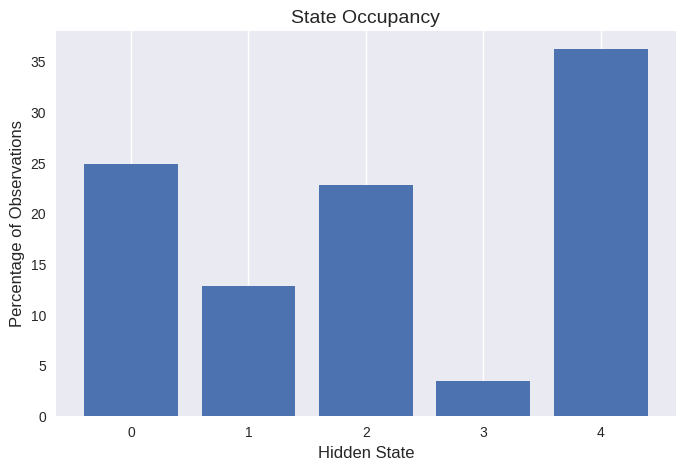

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(occupancy.index.astype(str),occupancy["Percentage"])
plt.xlabel("Hidden State")
plt.ylabel("Percentage of Observations")
plt.title("State Occupancy")
plt.grid(axis="y")
plt.show()

#### **Display Transition Matrix**
This cell extracts the transition matrix from the `best_model` and presents it as a pandas DataFrame. The transition matrix shows the probabilities of moving from one hidden state to another on the next observation.

In [ ]:
transition_matrix = pd.DataFrame(best_model.transmat_,index=[f"State {i}" for i in range(best_model.n_components)],
    columns=[f"State {i}" for i in range(best_model.n_components)])

transition_matrix

,State 0,State 1,State 2,State 3,State 4
State 0,9.690456e-01,2.289851e-03,1.177401e-02,1.152638e-03,1.573790e-02
State 1,1.039565e-02,9.867134e-01,5.809129e-110,5.868424e-127,2.890919e-03
State 2,1.588174e-02,4.442536e-31,9.712645e-01,2.879575e-03,9.974200e-03
State 3,2.950272e-155,2.216896e-02,5.556634e-03,9.722744e-01,1.113343e-191
State 4,8.077660e-03,1.044444e-03,9.534051e-03,1.873905e-160,9.813438e-01


#### **Verify Transition Matrix Sums**
This cell calculates the sum of probabilities for each row in the transition matrix. The sum of probabilities from any given state to all other states (including itself) should ideally be 1.0, confirming the matrix's validity.

In [ ]:
transition_matrix.sum(axis=1)

,0
State 0,1.0
State 1,1.0
State 2,1.0
State 3,1.0
State 4,1.0


#### **Visualize Transition Matrix**
This cell uses a heatmap to visually represent the transition probabilities between hidden states, making it easier to identify which state transitions are more likely.

Text(45.722222222222214, 0.5, 'Current State')

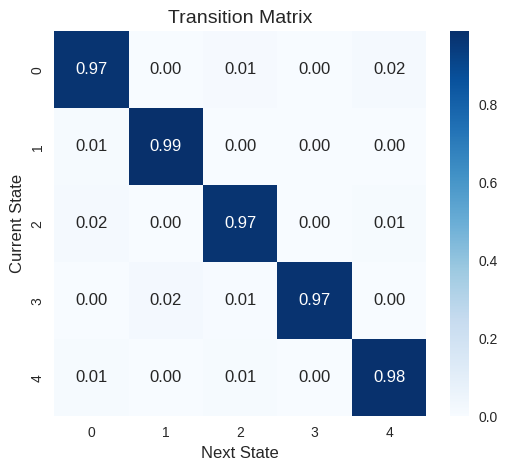

In [ ]:
plt.figure(figsize=(6,5))

sns.heatmap(
    best_model.transmat_,
    annot=True,
    cmap="Blues",
    fmt=".2f")

plt.title("Transition Matrix")
plt.xlabel("Next State")
plt.ylabel("Current State")

#### **Calculate Expected Duration in States**
This cell calculates the expected duration (in days) that the system will remain in each hidden state. This is derived from the diagonal elements of the transition matrix, where `P(stay in state i) = diag(transmat)[i]` and `Expected Duration = 1 / (1 - P(stay in state i))`.

In [ ]:
expected_duration = pd.DataFrame({"Stay Probability": np.diag(best_model.transmat_),
    "Expected Duration (Days)": 1 / (1 - np.diag(best_model.transmat_))})

expected_duration.index = [f"State {i}" for i in range(best_model.n_components)]
expected_duration

,Stay Probability,Expected Duration (Days)
State 0,0.969046,32.305584
State 1,0.986713,75.263964
State 2,0.971264,34.800138
State 3,0.972274,36.067758
State 4,0.981344,53.601614


#### **Visualize Expected Regime Duration**
This cell generates a bar plot illustrating the expected number of days the market is likely to remain in each identified hidden regime, providing a clear visual summary of regime persistence.

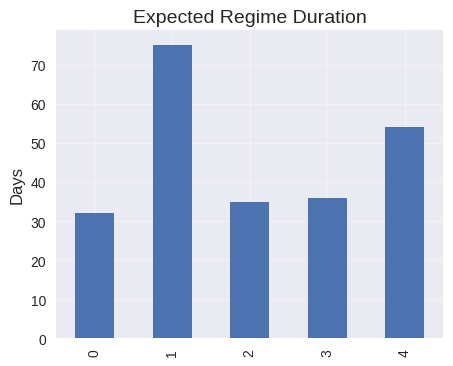

In [ ]:
duration = pd.Series({0:32,1:75,2:35,3:36,4:54})
duration.plot.bar(figsize=(5,4))
plt.ylabel("Days")
plt.title("Expected Regime Duration")
plt.grid(alpha=0.3)

#### **Prepare Data for Regime Analysis**
This cell creates a new DataFrame (`analysis_df`) by copying the original `features` and adds a new column 'Regime' containing the predicted hidden states. This DataFrame will be used for further analysis of each regime.

In [ ]:
analysis_df = features.loc[X_scaled.index].copy()
analysis_df["Regime"] = hidden_states

#### **Summarize Regimes by Mean Feature Values**
This cell groups the `analysis_df` by the 'Regime' column and calculates the mean of all features for each regime. This helps characterize the typical market conditions (returns, volatility, momentum, etc.) associated with each hidden state.

In [ ]:
regime_summary = (analysis_df.groupby("Regime").mean())
regime_summary

,GLD_Return,SPY_Return,TLT_Return,VIX_Return,GLD_Vol20,SPY_Vol20,TLT_Vol20,VIX_Vol20,GLD_Vol63,SPY_Vol63,...,GLD_Mom20,SPY_Mom20,TLT_Mom20,VIX_Mom20,GLD_Mom63,SPY_Mom63,TLT_Mom63,VIX_Mom63,SPY_TLT_Corr20,VIX_Level
Regime,,,,,,,,,,,,,,,,,,,,,
0,0.000022,0.000378,-0.000324,0.001377,0.010223,0.008846,0.008072,0.073087,0.010802,0.009949,...,0.006994,0.014176,-0.008621,0.049630,0.042299,0.053674,0.011891,0.022674,-0.158301,19.508710
1,0.000146,0.000726,-0.000257,-0.003971,0.011790,0.015469,0.012961,0.064995,0.012695,0.018647,...,0.006396,0.016342,-0.008438,-0.050767,0.038123,0.005281,-0.018989,0.012291,-0.154183,27.575487
2,0.000469,0.000240,0.000752,-0.000819,0.010603,0.010559,0.007813,0.081586,0.010270,0.009698,...,0.010573,-0.001262,0.024333,0.061471,0.034662,0.001086,0.045878,0.166550,-0.603844,19.434512
3,0.002313,-0.002902,0.002318,0.007727,0.021408,0.035530,0.016988,0.134175,0.018094,0.026436,...,0.039593,-0.083087,0.059299,0.657220,0.046457,-0.154872,0.109586,1.443061,-0.517439,46.175167
4,0.000556,0.000756,-0.000060,0.000439,0.009079,0.005784,0.007013,0.058936,0.009498,0.006368,...,0.009099,0.019313,-0.003694,-0.023651,0.016037,0.056327,-0.013485,-0.069952,-0.092094,13.522776


#### **Display Selected Regime Summaries**
This cell selects a specific subset of summary columns (e.g., SPY returns, volatilities, VIX) from the `regime_summary` to highlight key characteristics of each hidden market regime, making it easier to interpret their financial implications.

In [ ]:
summary_columns = ["SPY_Return", "TLT_Return", "SPY_Vol20", "SPY_Vol63", "SPY_Mom20", "SPY_Mom63", "SPY_TLT_Corr20", "VIX_Level"]
regime_summary[summary_columns]

,SPY_Return,TLT_Return,SPY_Vol20,SPY_Vol63,SPY_Mom20,SPY_Mom63,SPY_TLT_Corr20,VIX_Level
Regime,,,,,,,,
0,0.000378,-0.000324,0.008846,0.009949,0.014176,0.053674,-0.158301,19.508710
1,0.000726,-0.000257,0.015469,0.018647,0.016342,0.005281,-0.154183,27.575487
2,0.000240,0.000752,0.010559,0.009698,-0.001262,0.001086,-0.603844,19.434512
3,-0.002902,0.002318,0.035530,0.026436,-0.083087,-0.154872,-0.517439,46.175167
4,0.000756,-0.000060,0.005784,0.006368,0.019313,0.056327,-0.092094,13.522776


#### **Prepare Data for Price Plotting**
This cell creates a copy of `analysis_df` named `plot_df` and adds the original 'SPY' closing prices, aligning them with the predicted regimes. This prepares the data for plotting SPY prices colored by regime.

In [ ]:
plot_df = analysis_df.copy()
plot_df["SPY_Price"] = prices.loc[plot_df.index, "SPY"]

#### **Define Regime Colors**
This cell defines a dictionary (`regime_colors`) to assign a distinct color to each hidden state. These colors will be used consistently in subsequent visualizations to differentiate the market regimes.

In [ ]:
regime_colors = {0: "royalblue", 1: "orange", 2: "green", 3: "red", 4: "purple"}

#### **Plot SPY Price (Base Layer)**
This cell initiates a plot by drawing the historical SPY closing prices as a black line. This serves as the base layer upon which the hidden market regimes will be overlaid.

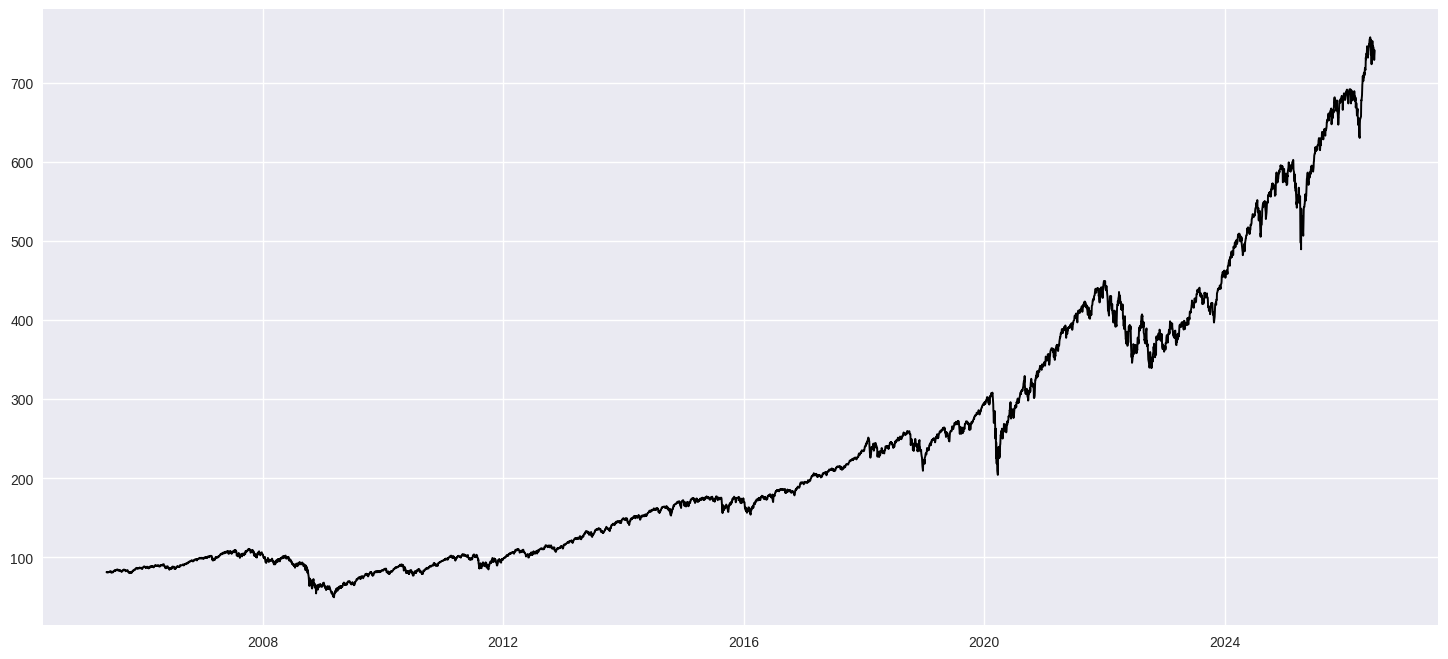

In [ ]:
plt.figure(figsize=(18,8))
plt.plot(plot_df.index, plot_df["SPY_Price"], color="black", linewidth=1.4, label="SPY")

#### **Overlay Regimes on SPY Price (Scatter Plot)**
This cell iterates through each hidden state and overlays scatter points on the SPY price chart, colored according to the `regime_colors`. Each scatter point represents a day, indicating the hidden state of the market on that day.

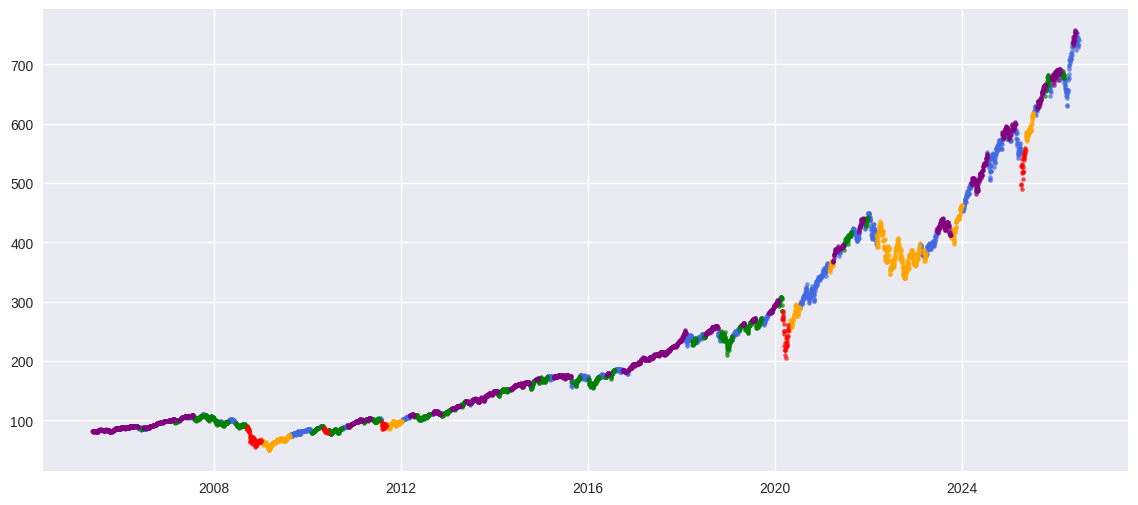

In [ ]:
for state in range(best_model.n_components):

    mask = plot_df["Regime"] == state

    plt.scatter(plot_df.index[mask], plot_df["SPY_Price"][mask], s=8, color=regime_colors[state], label=f"State {state}", alpha=0.7)

#### **Overlay Regimes on SPY Price (Scatter Plot with Titles and Legends)**
This cell refines the previous plot by adding titles, axis labels, a legend, and a grid, ensuring the visualization of SPY prices with overlaid hidden regimes is complete and easily interpretable. It displays the plots for each state individually.

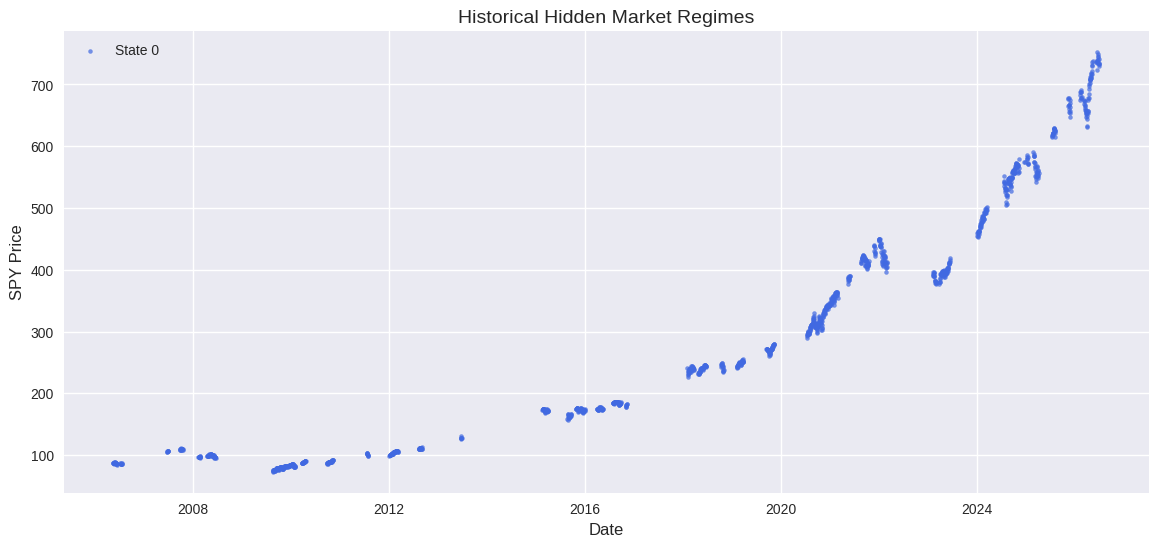

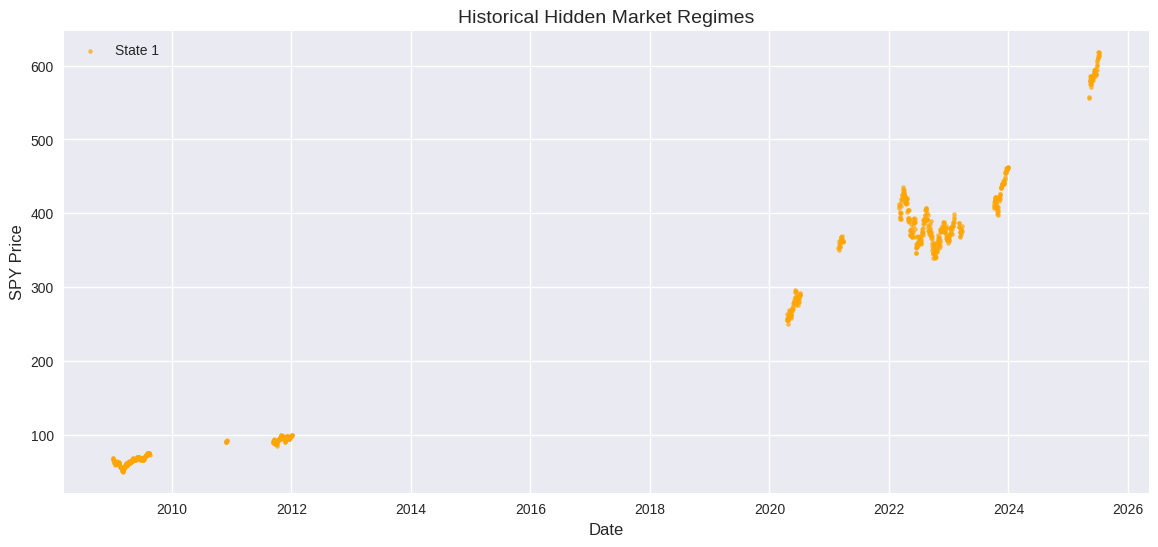

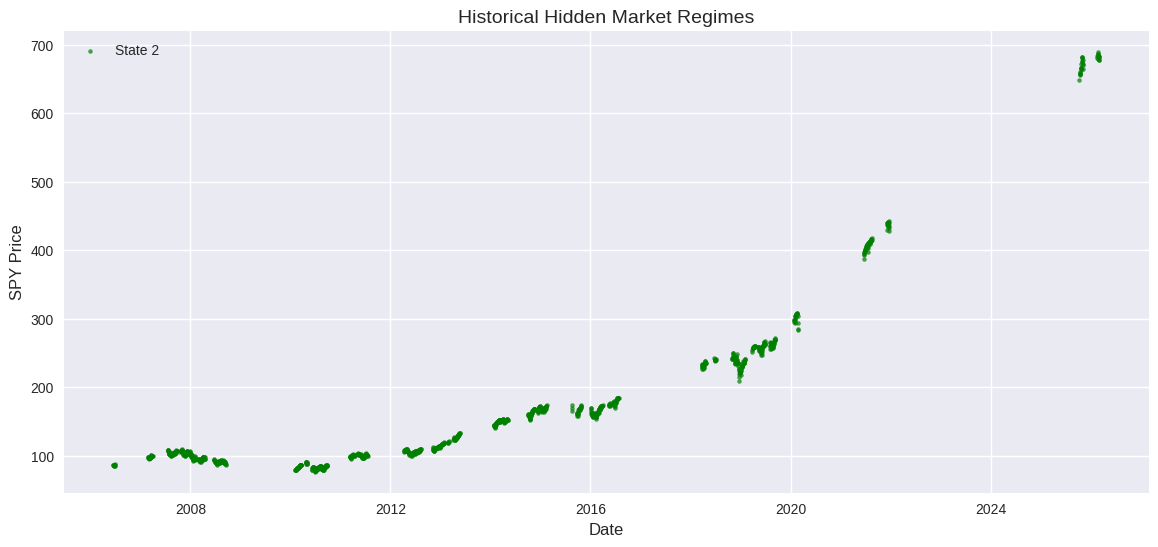

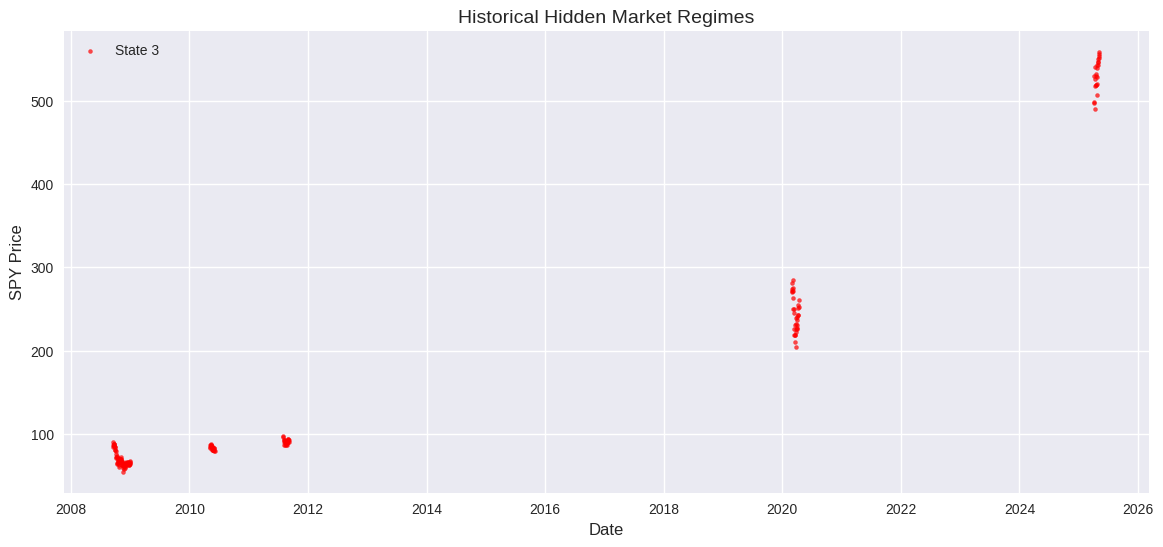

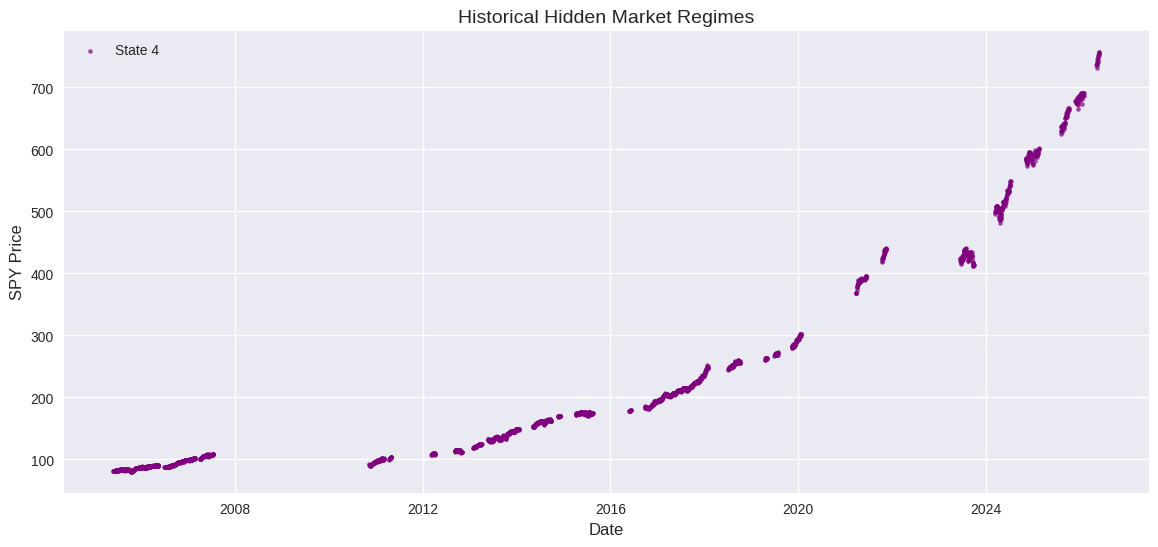

In [ ]:
for state in range(best_model.n_components):

    mask = plot_df["Regime"] == state

    plt.scatter(plot_df.index[mask], plot_df["SPY_Price"][mask], s=8, color=regime_colors[state], label=f"State {state}", alpha=0.7)
    plt.title("Historical Hidden Market Regimes")
    plt.xlabel("Date")
    plt.ylabel("SPY Price")
    plt.legend()
    plt.grid(True)
    plt.show()

#### **Distribution of SPY Returns by Regime**
This cell generates histograms for SPY daily returns, separated by each hidden regime. This visualization helps to understand how the distribution of SPY returns varies across different market states, potentially revealing regimes with higher or lower average returns and different levels of volatility.

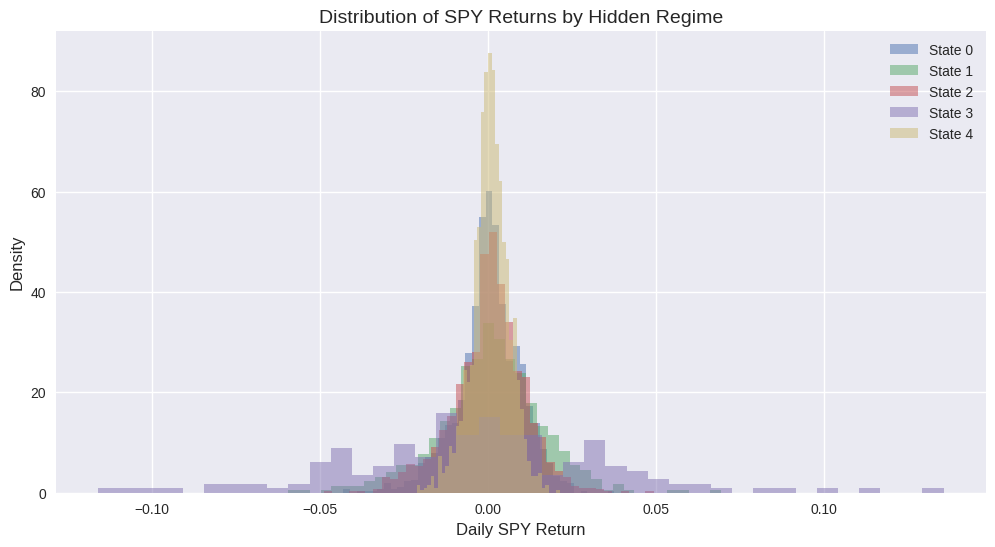

In [ ]:
plt.figure(figsize=(12,6))

for state in sorted(analysis_df["Regime"].unique()):

    plt.hist(

        analysis_df.loc[
            analysis_df["Regime"]==state,
            "SPY_Return"
        ],

        bins=40,

        alpha=0.5,

        density=True,

        label=f"State {state}")

plt.title("Distribution of SPY Returns by Hidden Regime")
plt.xlabel("Daily SPY Return")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

#### **Distribution of 20-Day SPY Volatility by Regime**
This cell creates histograms for the 20-day rolling volatility of SPY, grouped by each hidden regime. This plot is essential for identifying regimes characterized by high versus low volatility in the SPY market.

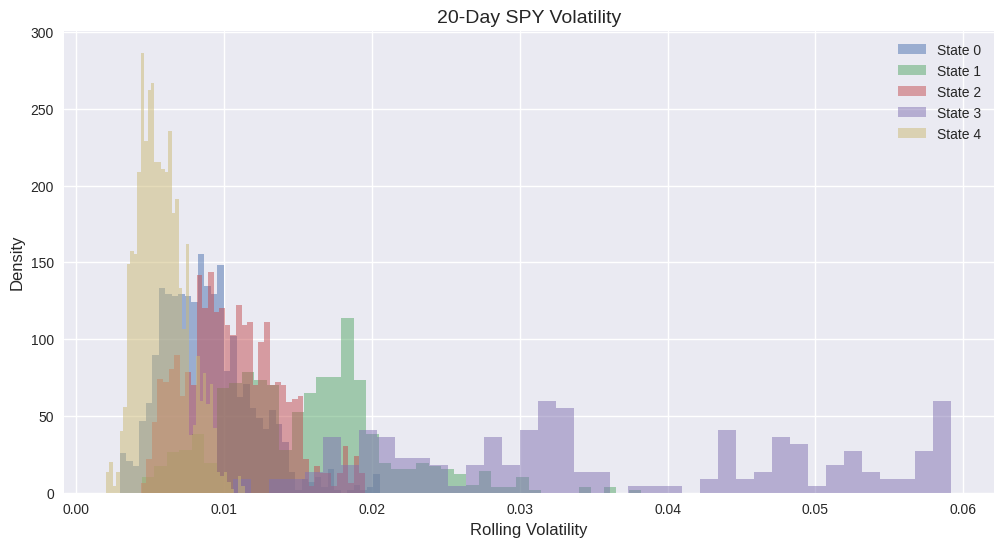

In [ ]:
plt.figure(figsize=(12,6))

for state in sorted(analysis_df["Regime"].unique()):

    plt.hist(

        analysis_df.loc[
            analysis_df["Regime"]==state,
            "SPY_Vol20"
        ],

        bins=40,

        alpha=0.5,

        density=True,

        label=f"State {state}")

plt.title("20-Day SPY Volatility")
plt.xlabel("Rolling Volatility")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

#### **VIX Distribution by Hidden Regime**
This cell plots histograms of the VIX (Volatility Index) levels for each hidden regime. This helps in understanding how VIX levels, a measure of market fear, are distributed across different market states, allowing for the identification of regimes associated with high or low market stress.

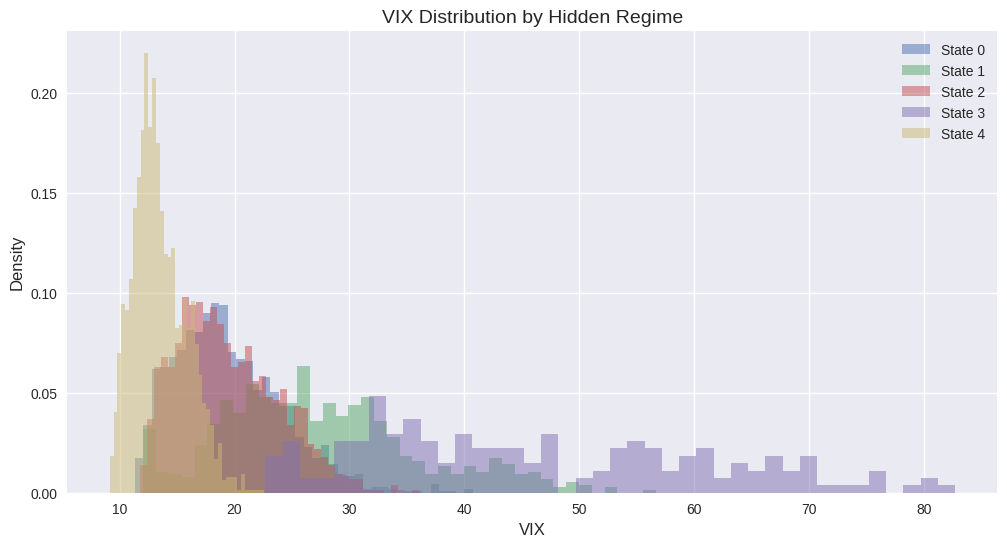

In [ ]:
plt.figure(figsize=(12,6))

for state in sorted(analysis_df["Regime"].unique()):

    plt.hist(

        analysis_df.loc[
            analysis_df["Regime"]==state,
            "VIX_Level"
        ],

        bins=40,

        alpha=0.5,

        density=True,

        label=f"State {state}")

plt.title("VIX Distribution by Hidden Regime")
plt.xlabel("VIX")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

#### **TLT Return Distribution by Hidden Regime**
This cell visualizes the distribution of daily returns for TLT (iShares 20+ Year Treasury Bond ETF) across different hidden market regimes using histograms. This helps in understanding how bond returns behave in various market states identified by the HMM.

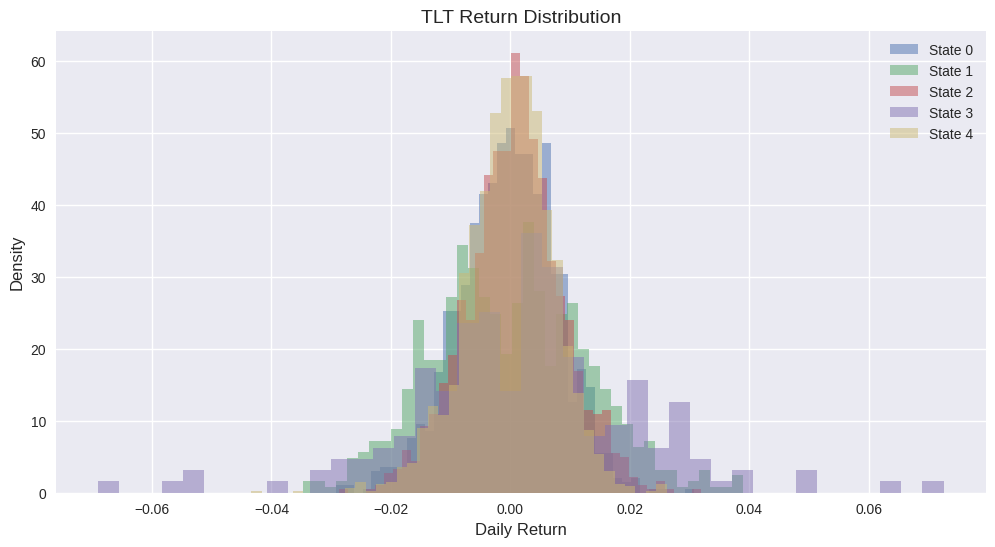

In [ ]:
plt.figure(figsize=(12,6))

for state in sorted(analysis_df["Regime"].unique()):

    plt.hist(

        analysis_df.loc[
            analysis_df["Regime"]==state,
            "TLT_Return"
        ],

        bins=40,

        alpha=0.5,

        density=True,

        label=f"State {state}")

plt.title("TLT Return Distribution")
plt.xlabel("Daily Return")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

#### **SPY Returns by Hidden Regime (Box Plot)**
This cell generates a box plot of SPY daily returns, grouped by each hidden regime. Box plots provide a concise visual summary of the distribution of returns within each regime, highlighting the median, quartiles, and potential outliers, offering further insights into the characteristics of each market state.

<Figure size 1000x600 with 0 Axes>

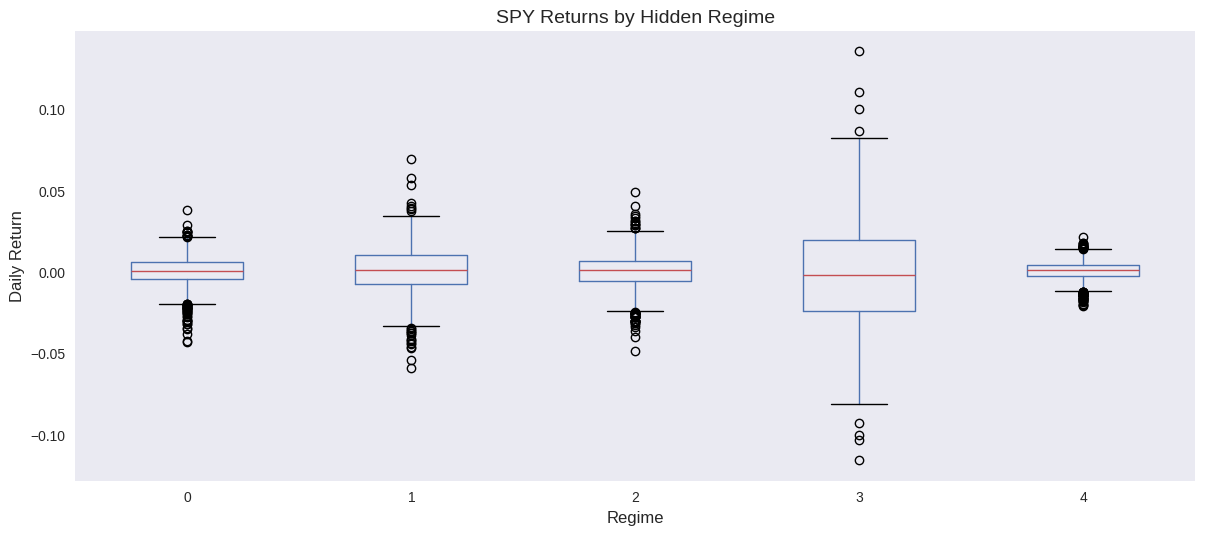

In [ ]:
plt.figure(figsize=(10,6))

analysis_df.boxplot(

    column="SPY_Return",

    by="Regime",

    grid=False)
plt.title("SPY Returns by Hidden Regime")
plt.suptitle("")
plt.xlabel("Regime")
plt.ylabel("Daily Return")
plt.show()

#### **SPY Price with Hidden Market Regimes (Time-Series Plot)**
This cell creates a comprehensive time-series plot of SPY prices, with shaded regions indicating the different hidden market regimes. This visualization clearly shows when each regime started and ended, providing a powerful visual representation of the market's transitions between states over time.

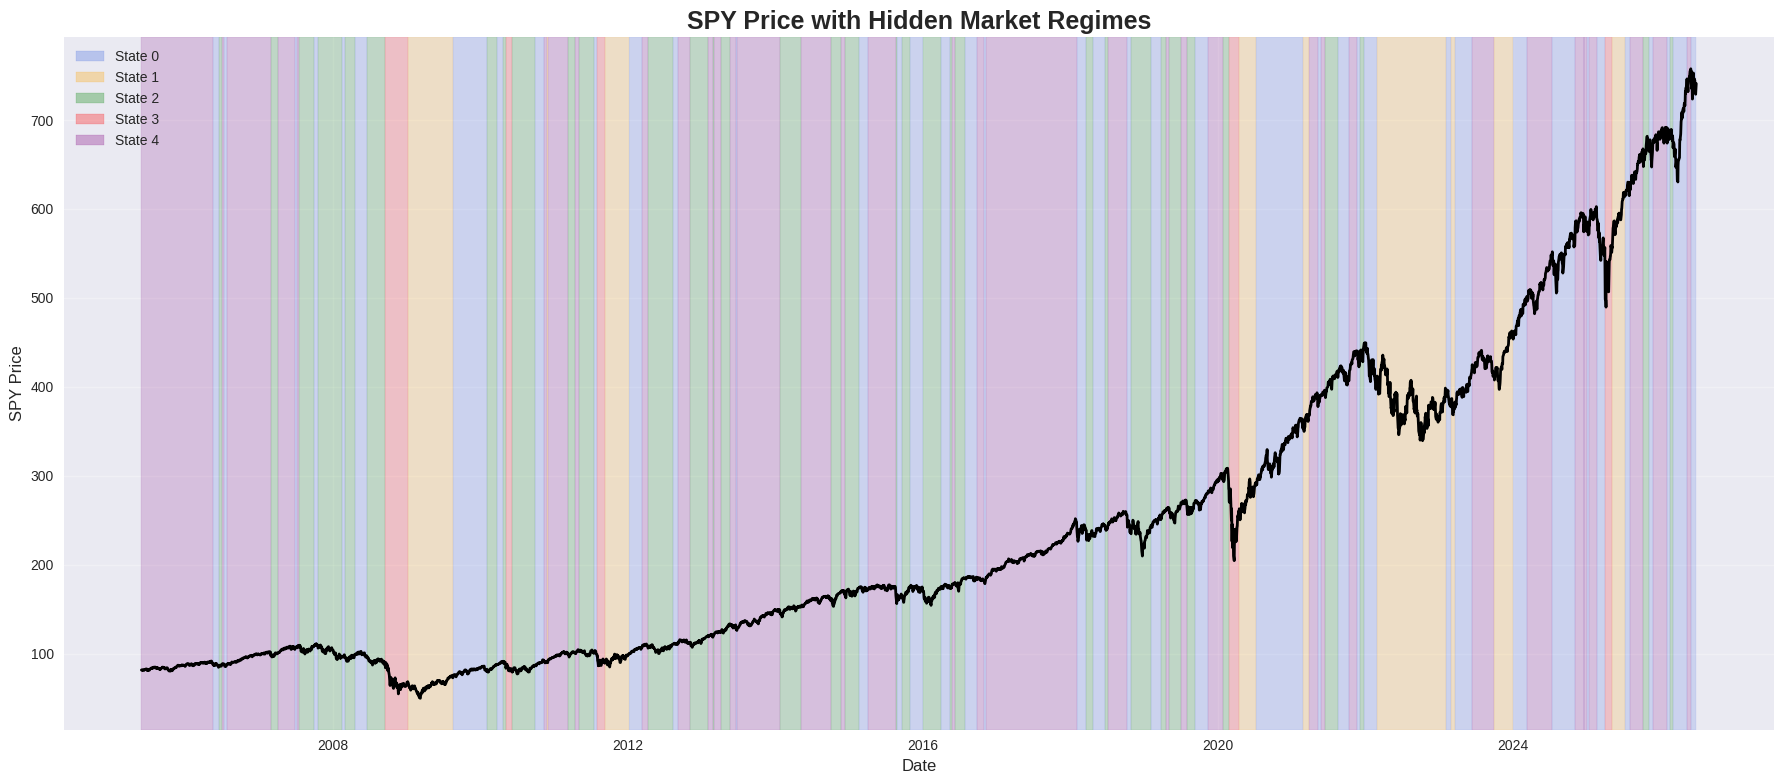

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plot_df = analysis_df.copy()
plot_df["SPY_Price"] = prices.loc[plot_df.index, "SPY"]

regime_colors = {
    0: "royalblue",
    1: "orange",
    2: "green",
    3: "red",
    4: "purple"}

plt.figure(figsize=(18,8))

# SPY price
plt.plot(
    plot_df.index,
    plot_df["SPY_Price"],
    color="black",
    linewidth=2,
    label="SPY"
)

current_regime = plot_df["Regime"].iloc[0]
start_date = plot_df.index[0]

for i in range(1, len(plot_df)):

    regime = plot_df["Regime"].iloc[i]

    if regime != current_regime:

        plt.axvspan(
            start_date,
            plot_df.index[i],
            color=regime_colors[current_regime],
            alpha=0.18
        )

        start_date = plot_df.index[i]
        current_regime = regime

plt.axvspan(
    start_date,
    plot_df.index[-1],
    color=regime_colors[current_regime],
    alpha=0.18
)

legend = [
    mpatches.Patch(color="royalblue", alpha=0.3, label="State 0"),
    mpatches.Patch(color="orange", alpha=0.3, label="State 1"),
    mpatches.Patch(color="green", alpha=0.3, label="State 2"),
    mpatches.Patch(color="red", alpha=0.3, label="State 3"),
    mpatches.Patch(color="purple", alpha=0.3, label="State 4")
]

plt.legend(handles=legend, loc="upper left")

plt.title(
    "SPY Price with Hidden Market Regimes",
    fontsize=18,
    weight="bold"
)

plt.xlabel("Date")
plt.ylabel("SPY Price")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()